In [1]:
# import
import os, sys, shutil, pickle
import numpy as np
import pandas as pd
import scipy as sp
import nibabel as nib
from tqdm import tqdm
from sklearn.linear_model import LinearRegression

sys.path.extend([r'/home/lindenmp/research_projects/snaplab_tools'])
from snaplab_tools.utils import threshold_consistency, normalize_x
from snaplab_tools.plotting.utils import get_my_colors, get_p_val_string

# import plotting libraries
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 8})
plt.rcParams["svg.fonttype"] = "none"
import seaborn as sns

## Load data

In [2]:
in_dir = '/mnt/storage_ssd_raid/research_data/HCP_YA/collated_outputs'

atlas = 'Schaefer4007'
if atlas == 'Schaefer4007':
    n_parcels = 400
elif atlas == 'Schaefer2007':
    n_parcels = 200
elif atlas == 'Schaefer1007':
    n_parcels = 100

### Connectome

In [3]:
# Load data (deserialize)
with open(os.path.join(in_dir, 'hcpya_connectome.pkl'), 'rb') as handle:
    data = pickle.load(handle)

data.keys()

dict_keys(['100206', '100307', '100408', '100610', '101006', '101107', '101309', '101915', '102008', '102109', '102311', '102513', '102614', '102715', '102816', '103111', '103212', '103414', '103515', '103818', '104012', '104416', '104820', '105014', '105115', '105216', '105620', '105923', '106016', '106319', '106521', '106824', '107018', '107321', '107422', '107725', '108020', '108121', '108222', '108323', '108525', '108828', '109123', '109830', '110007', '110411', '110613', '111009', '111211', '111312', '111413', '111514', '111716', '112112', '112314', '112516', '112920', '113215', '113316', '113619', '113922', '114217', '114318', '114419', '114621', '114823', '115017', '115219', '115320', '115724', '115825', '116524', '116726', '117021', '117122', '117324', '117930', '118023', '118124', '118225', '118528', '118730', '118831', '118932', '119025', '119126', '119732', '119833', '120111', '120212', '120414', '120515', '120717', '121416', '121618', '121921', '122317', '122620', '122822',

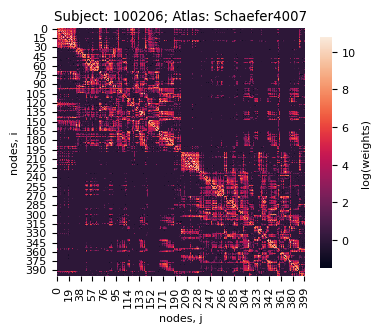

In [4]:
subject_id = '100206'
# atlas = '4S456Parcels'
atlas = 'Schaefer4007'
adjacency = data[subject_id][atlas]
adjacency_log = np.log(adjacency, out=np.zeros_like(adjacency), where=(adjacency != 0))

f, ax = plt.subplots(figsize=(4, 4))
sns.heatmap(adjacency_log, ax=ax, square=True, cbar_kws={'shrink': 0.75, 'label': 'log(weights)'})
ax.set_ylabel('nodes, i')
ax.set_xlabel('nodes, j')
ax.set_title('Subject: {0}; Atlas: {1}'.format(subject_id, atlas))
plt.show()

f.savefig('/home/lindenmp/connectome_100206.png', dpi=600, bbox_inches="tight", pad_inches=0.01)


In [5]:
subject_ids = list(data.keys())
n_subs = len(subject_ids)
n_subs

962

In [6]:
subject_filter = np.zeros(n_subs).astype(bool)

In [7]:
parc_dir = '/mnt/storage_ssd_raid/research_data/HCP_YA/derivatives/parcellations'

A = np.zeros((n_parcels, n_parcels, n_subs))

for i in np.arange(n_subs):
    try:
        adj = data[subject_ids[i]][atlas].copy()
        
        in_file = os.path.join(parc_dir, '{0}/{0}_atlas-{1}_space-T1w_res-1_regionsizes.txt'.format(subject_ids[i], atlas))
        voxel_counts = np.loadtxt(in_file, dtype=int)
        voxel_counts = normalize_x(voxel_counts) + 1e-5
        size_matrix = np.add.outer(voxel_counts, voxel_counts) / 2
        adj = np.divide(adj, size_matrix)
        adj_mask = adj > 0
        adj[adj_mask] += 1
        adj = np.log(adj, out=np.zeros_like(adj), where=(adj != 0))

        A[:, :, i] = adj
    except:
        subject_filter[i] = True
        
print(np.sum(subject_filter))

0


In [8]:
print(np.any(A < 0))
print(np.any(np.isinf(A)))
print(np.any(np.isnan(A)))

False
False
False


### rest fmri

In [9]:
# Load data (deserialize)
with open(os.path.join(in_dir, 'hcpya_rsfmri.pkl'), 'rb') as handle:
    data = pickle.load(handle)

data.keys()

dict_keys(['100206', '100307', '100408', '100610', '101006', '101107', '101309', '101915', '102008', '102109', '102311', '102513', '102614', '102715', '102816', '103111', '103212', '103414', '103515', '103818', '104012', '104416', '104820', '105014', '105115', '105216', '105620', '105923', '106016', '106319', '106521', '106824', '107018', '107321', '107422', '107725', '108020', '108121', '108222', '108323', '108525', '108828', '109123', '109830', '110007', '110411', '110613', '111009', '111211', '111312', '111413', '111514', '111716', '112112', '112314', '112516', '112920', '113215', '113316', '113619', '113922', '114217', '114318', '114419', '114621', '114823', '115017', '115219', '115320', '115724', '115825', '116524', '116726', '117021', '117122', '117324', '117930', '118023', '118124', '118225', '118528', '118730', '118831', '118932', '119025', '119126', '119732', '119833', '120111', '120212', '120414', '120515', '120717', '121416', '121618', '121921', '122317', '122620', '122822',

In [10]:
data['100206']['Schaefer4007'].keys()

dict_keys(['rfMRIREST1LR', 'rfMRIREST1RL', 'rfMRIREST2LR', 'rfMRIREST2RL'])

In [11]:
scans = [
    'rfMRIREST1LR',
    'rfMRIREST2LR',
    'rfMRIREST1RL',
    'rfMRIREST2RL'
    ]

In [12]:
rsts = np.zeros((1200, n_parcels, len(scans), n_subs))

for s, scan in enumerate(scans):
    print(scan)
    for i in tqdm(np.arange(n_subs)):
        try:
            ts = data[subject_ids[i]][atlas][scan].copy()
            
            gs = np.mean(ts, axis=1).reshape(-1, 1)
            gs_diff = np.append(0, np.diff(gs, axis=0)).reshape(-1, 1)
            nuis = np.concatenate((gs, gs_diff), axis=1)
            nuis = np.concatenate((nuis, np.square(nuis)), axis=1)

            regr = LinearRegression()
            regr.fit(nuis, ts)
            y_pred = regr.predict(nuis)
            ts = ts - y_pred
            
            # z score
            ts = sp.stats.zscore(ts, axis=0)
            
            if np.any(np.isnan(ts)):
                print('Found NaNs!')
            if np.any(np.isinf(ts)):
                print('Found infs!')

            rsts[:, :, s, i] = ts
        except:
            subject_filter[i] = True
    print(np.sum(subject_filter))

print(np.sum(subject_filter))

rfMRIREST1LR


100%|██████████| 962/962 [00:14<00:00, 67.17it/s]


2
rfMRIREST2LR


100%|██████████| 962/962 [00:13<00:00, 71.61it/s]


8
rfMRIREST1RL


100%|██████████| 962/962 [00:12<00:00, 74.70it/s]


9
rfMRIREST2RL


100%|██████████| 962/962 [00:11<00:00, 80.34it/s]

11
11


### task fmri

In [13]:
# Load data (deserialize)
with open(os.path.join(in_dir, 'hcpya_tfmri.pkl'), 'rb') as handle:
    data = pickle.load(handle)

data.keys()

dict_keys(['100206', '100307', '100408', '100610', '101006', '101107', '101309', '101915', '102008', '102109', '102311', '102513', '102614', '102715', '102816', '103111', '103212', '103414', '103515', '103818', '104012', '104416', '104820', '105014', '105115', '105216', '105620', '105923', '106016', '106319', '106521', '106824', '107018', '107321', '107422', '107725', '108020', '108121', '108222', '108323', '108525', '108828', '109123', '109830', '110007', '110411', '110613', '111009', '111211', '111312', '111413', '111514', '111716', '112112', '112314', '112516', '112920', '113215', '113316', '113619', '113922', '114217', '114318', '114419', '114621', '114823', '115017', '115219', '115320', '115724', '115825', '116524', '116726', '117021', '117122', '117324', '117930', '118023', '118124', '118225', '118528', '118730', '118831', '118932', '119025', '119126', '119732', '119833', '120111', '120212', '120414', '120515', '120717', '121416', '121618', '121921', '122317', '122620', '122822',

In [14]:
scans = [
    'tfMRIEMOTIONLR',
    'tfMRIGAMBLINGLR',
    'tfMRILANGUAGELR',
    'tfMRIMOTORLR',
    'tfMRIRELATIONALLR',
    'tfMRISOCIALLR',
    'tfMRIWMLR',
    'tfMRIEMOTIONRL',
    'tfMRIGAMBLINGRL',
    'tfMRILANGUAGERL',
    'tfMRIMOTORRL',
    'tfMRIRELATIONALRL',
    'tfMRISOCIALRL',
    'tfMRIWMRL'
    ]
taskts_dict = dict()

In [15]:
taskts = np.zeros((1, n_parcels, n_subs))

for scan in scans:
    n_trs_task = data[subject_ids[0]][atlas][scan].shape[0]
    print(scan, n_trs_task)
    taskts_tmp = np.zeros((n_trs_task, n_parcels, n_subs))
    for i in tqdm(np.arange(n_subs)):
        try:
            ts = data[subject_ids[i]][atlas][scan].copy()
            
            gs = np.mean(ts, axis=1).reshape(-1, 1)
            gs_diff = np.append(0, np.diff(gs, axis=0)).reshape(-1, 1)
            nuis = np.concatenate((gs, gs_diff), axis=1)
            nuis = np.concatenate((nuis, np.square(nuis)), axis=1)

            regr = LinearRegression()
            regr.fit(nuis, ts)
            y_pred = regr.predict(nuis)
            ts = ts - y_pred
            
            # z score
            ts = sp.stats.zscore(ts, axis=0)
            
            if np.any(np.isnan(ts)):
                print('Found NaNs!')
            if np.any(np.isinf(ts)):
                print('Found infs!')

            taskts_tmp[:, :, i] = ts
        except:
            subject_filter[i] = True
    
    taskts = np.concatenate((taskts, taskts_tmp.copy()), axis=0)
    taskts_dict[scan] = taskts_tmp.copy()
    print(np.sum(subject_filter))

taskts = taskts[1:]
print(np.sum(subject_filter))

tfMRIEMOTIONLR 176


100%|██████████| 962/962 [00:01<00:00, 526.76it/s]


12
tfMRIGAMBLINGLR 253


100%|██████████| 962/962 [00:02<00:00, 380.83it/s]


13
tfMRILANGUAGELR 316


...

15
tfMRISOCIALRL 274


100%|██████████| 962/962 [00:02<00:00, 375.52it/s]


15
tfMRIWMRL 405


100%|██████████| 962/962 [00:03<00:00, 244.88it/s]


15
15


### myelin

In [16]:
# Load data (deserialize)
with open(os.path.join(in_dir, 'hcpya_myelin.pkl'), 'rb') as handle:
    data = pickle.load(handle)

data.keys()

dict_keys(['100206', '100307', '100408', '100610', '101006', '101107', '101309', '101915', '102008', '102109', '102311', '102513', '102614', '102715', '102816', '103111', '103212', '103414', '103515', '103818', '104012', '104416', '104820', '105014', '105115', '105216', '105620', '105923', '106016', '106319', '106521', '106824', '107018', '107321', '107422', '107725', '108020', '108121', '108222', '108323', '108525', '108828', '109123', '109830', '110007', '110411', '110613', '111009', '111211', '111312', '111413', '111514', '111716', '112112', '112314', '112516', '112920', '113215', '113316', '113619', '113922', '114217', '114318', '114419', '114621', '114823', '115017', '115219', '115320', '115724', '115825', '116524', '116726', '117021', '117122', '117324', '117930', '118023', '118124', '118225', '118528', '118730', '118831', '118932', '119025', '119126', '119732', '119833', '120111', '120212', '120414', '120515', '120717', '121416', '121618', '121921', '122317', '122620', '122822',

In [17]:
myelin = np.zeros((n_parcels, n_subs))

for i in np.arange(n_subs):
    try:
        myelin[:, i] = data[subject_ids[i]][atlas]
    except:
        subject_filter[i] = True
        
print(np.sum(subject_filter))

15


## Filter

In [18]:
np.asarray(subject_ids)[subject_filter]

array(['119732', '119833', '136126', '159946', '169747', '183337',
       '202820', '284646', '317332', '329440', '547046', '644246',
       '713239', '751550', '786569'], dtype='<U6')

In [19]:
A = A[:, :, ~subject_filter]
rsts = rsts[:, :, :, ~subject_filter]
myelin = myelin[:, ~subject_filter]
for scan in taskts_dict.keys():
    taskts_dict[scan] = taskts_dict[scan][:, :, ~subject_filter]

try:
    tasksts = taskts[:, :, ~subject_filter]
    print(A.shape, rsts.shape, myelin.shape, tasksts.shape)
except:
    print(A.shape, rsts.shape, myelin.shape)

(400, 400, 947) (1200, 400, 4, 947) (400, 947) (3880, 400, 947)


In [20]:
try:
    for scan in taskts_dict.keys():
        print(taskts_dict[scan].shape)
except:
    pass

(176, 400, 947)
(253, 400, 947)
(316, 400, 947)
(284, 400, 947)
(232, 400, 947)
(274, 400, 947)
(405, 400, 947)
(176, 400, 947)
(253, 400, 947)
(316, 400, 947)
(284, 400, 947)
(232, 400, 947)
(274, 400, 947)
(405, 400, 947)


In [21]:
Am = threshold_consistency(A, thr=0.6)
print(Am.shape)

(400, 400)


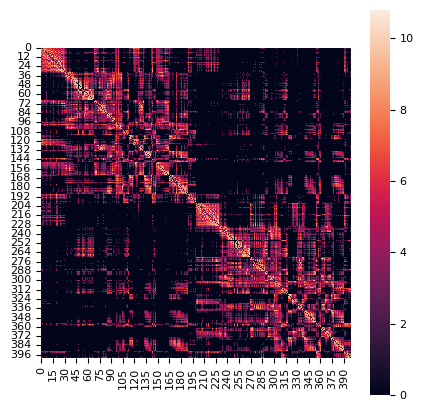

In [22]:
f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(Am, ax=ax, square=True)
plt.show()

In [23]:
np.count_nonzero(np.triu(Am)) / ((Am.shape[0] ** 2 - Am.shape[0]) / 2)

0.3282832080200501

In [24]:
print(np.any(Am < 0))
print(np.any(np.isinf(Am)))
print(np.any(np.isnan(Am)))

False
False
False


## Save

In [25]:
outdir = '/home/lindenmp/research_projects/intrinsic_neural_timescales/data'
if not os.path.exists(outdir):
    os.makedirs(outdir)

In [26]:
# save
file_str = os.path.join(outdir, 'HCP-YA_{0}_A.npy'.format(atlas))
np.save(file_str, A)
file_str = os.path.join(outdir, 'HCP-YA_{0}_Am.npy'.format(atlas))
np.save(file_str, Am)
file_str = os.path.join(outdir, 'HCP-YA_{0}_myelin.npy'.format(atlas))
np.save(file_str, myelin)
file_str = os.path.join(outdir, 'HCP-YA_{0}_rsts.npy'.format(atlas))
np.save(file_str, rsts)
for scan in taskts_dict.keys():
    file_str = os.path.join(outdir, 'HCP-YA_{0}_taskts-{1}.npy'.format(atlas, scan))
    np.save(file_str, taskts_dict[scan])

In [27]:
file_str = os.path.join(outdir, 'HCP-YA_{0}_subjids.txt'.format(atlas))
subject_ids_filt = np.asarray(subject_ids)[~subject_filter]
np.savetxt(file_str, subject_ids_filt, fmt='%s')